#  Break the Spam Filter
**AWS AI/ML Cohort · Week 3 hands-on task**

**Name:** Hana Berhe

**Goal.** Train the simple spam detector from the slides. Then try to fool it, and explain *why* it fails. At the end, I also try to make it stronger.

| Step | What I do |
|---|---|
| 1 | Load the SMS Spam Collection |
| 2 | Look at the data |
| 3 | Clean it and split it (train / validation / test) |
| 4 | Train the 10-line model and measure it |
| 5 | Break it with 5 messages |
| 6 | Look inside the model to see why it failed |
| 7 | Try to fix it |
| 8 | What I learned |

**Dataset:** [SMS Spam Collection (UCI)](https://archive.ics.uci.edu/dataset/228/sms+spam+collection), 5,574 text messages. `ham` means "not spam". The data is **not** stored in this repo. The notebook downloads it the first time it runs.

In [15]:
import csv
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

## 1. Load the data

The file is a **TSV** (tab-separated values): one message per line, with the label first, then a tab, then the text.

One small problem: some messages contain the `"` character. If pandas uses its default quote rules, it joins neighbour messages and **silently loses rows**. So I use `quoting=csv.QUOTE_NONE`. After loading, I check that I really have 5,574 rows.

In [16]:
DATA_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
DATA_PATH = "data/sms.tsv"

os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH, sep="\t", header=None,
                 names=["label", "message"], quoting=csv.QUOTE_NONE)

print("Rows, columns:", df.shape)
assert len(df) == 5574, "Row count is not 5,574. Check the loading step."
df.head()

Rows, columns: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 2. Look at the data first

Before I build any model, I want to know what the data looks like. Three questions:

1. How many messages are spam and how many are ham?
2. Are there duplicate messages?
3. Do spam messages look different from ham messages (for example, longer)?

label
ham     4827
spam     747
Name: count, dtype: int64
Spam share: 0.134
Duplicate rows: 403

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4827.0   71.5  58.3   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.7  28.9  13.0  133.0  149.0  157.0  223.0


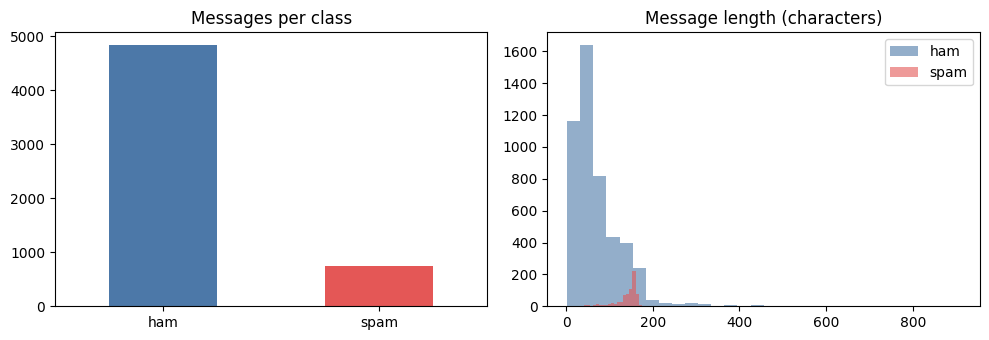

In [17]:
print(df["label"].value_counts())
print("Spam share:", round((df["label"] == "spam").mean(), 3))
print("Duplicate rows:", df.duplicated().sum())

df["length"] = df["message"].str.len()
print()
print(df.groupby("label")["length"].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

df["label"].value_counts().plot.bar(ax=ax[0], color=["#4c78a8", "#e45756"], rot=0)
ax[0].set_title("Messages per class")
ax[0].set_xlabel("")

for lab, color in [("ham", "#4c78a8"), ("spam", "#e45756")]:
    ax[1].hist(df.loc[df["label"] == lab, "length"], bins=30, alpha=0.6,
               label=lab, color=color)
ax[1].set_title("Message length (characters)")
ax[1].legend()

plt.tight_layout()
plt.show()

**What I see**

- Only about **13%** of the messages are spam. The data is *imbalanced*. This is very important when I read accuracy later.
- Many messages are **duplicates**. If the same message is in the training set *and* the test set, the model has already "seen the answer", and the test score looks better than it really is.
- Spam messages are usually **longer** than ham messages.

## 3. Clean and split

**Step 1: remove duplicates.** I remove them *before* splitting, so the same message can never be in two parts.

**Step 2: split into 3 parts** (like the lecture):

| Part | Size | Job |
|---|---|---|
| Train | 70% | the model learns here (practice questions) |
| Validation | 15% | I compare models and tune settings here (mock exam) |
| Test | 15% | I use it **once**, at the very end (real exam) |

I use `stratify=` so each part has the same spam share. `random_state=42` makes the split the same every time I run it.

Note: my numbers will be a little different from the slides, because I removed duplicates.

In [18]:
clean = df.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)
print("Rows before:", len(df), "| after removing duplicates:", len(clean))

train_df, temp_df = train_test_split(
    clean, test_size=0.30, random_state=42, stratify=clean["label"])
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"])

X_train, y_train = train_df["message"], train_df["label"]
X_val,   y_val   = val_df["message"],   val_df["label"]
X_test,  y_test  = test_df["message"],  test_df["label"]

summary = pd.DataFrame({
    "messages": [len(train_df), len(val_df), len(test_df)],
    "spam share": [round((y == "spam").mean(), 3) for y in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
summary

Rows before: 5574 | after removing duplicates: 5171


,messages,spam share
train,3619,0.126
validation,776,0.126
test,776,0.126


## 4. The 10-line model (slide 6)

Three ideas:

- **TF-IDF** turns each message into numbers. A word gets a high score if it is frequent in *this* message but rare in *other* messages.
- **Naive Bayes** is a fast classifier. For every word, it learns: "how much more common is this word in spam than in ham?" Then it adds up the evidence from all words in the message.
- `fit()` is the learning step.

In [19]:
vec = TfidfVectorizer()                                    # text -> numbers (features)
model = MultinomialNB()                                    # simple, fast classifier
model.fit(vec.fit_transform(X_train), y_train)             # learn

print("Trained on", len(X_train), "messages.")

Trained on 3619 messages.


### Measure it

I compare **train** and **validation** accuracy to check for overfitting. Then I look at precision and recall. The test set stays closed for now.

In [20]:
def evaluate(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy":  round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred, pos_label="spam", zero_division=0), 4),
        "recall":    round(recall_score(y_true, y_pred, pos_label="spam", zero_division=0), 4),
        "f1":        round(f1_score(y_true, y_pred, pos_label="spam", zero_division=0), 4),
    }

def confusion(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=["spam", "ham"])
    return pd.DataFrame(cm, index=["actually spam", "actually ham"],
                        columns=["predicted spam", "predicted ham"])

pred_train = model.predict(vec.transform(X_train))
pred_val = model.predict(vec.transform(X_val))

print("train accuracy:     ", round(accuracy_score(y_train, pred_train), 4))
print("validation accuracy:", round(accuracy_score(y_val, pred_val), 4))
print("'always say ham' would score:", round((y_val == "ham").mean(), 4))
print()

display(pd.DataFrame([evaluate("baseline (slide 6)", y_val, pred_val)]))
confusion(y_val, pred_val)

train accuracy:      0.9663
validation accuracy: 0.9472
'always say ham' would score: 0.8737



,model,accuracy,precision,recall,f1
0,baseline (slide 6),0.9472,1.0,0.5816,0.7355


,predicted spam,predicted ham
actually spam,57,41
actually ham,0,678


**How to read these numbers**

- **Train vs validation accuracy.** If train is much higher than validation, the model memorised (overfitting). If both are low, it is too simple (underfitting).
- **The accuracy trap.** A model that *always* says "ham" already gets a high accuracy, because most messages are ham. So a good-looking accuracy means very little here.
- **Precision:** of the messages I marked spam, how many were really spam? (Low precision = good messages are lost.)
- **Recall:** of all real spam, how many did I catch? (Low recall = spam gets through.)
- **F1:** one number that mixes precision and recall.

✍️ **My reading of my own numbers**
 My model got 96.6% accuracy on train and 94.7% on validation. These two numbers are close, so the model is not overfitting.

But a model that always says "ham" already gets 87.4%. So my 94.7% is only a little better than that.

Precision is 1.0, so the model never marked a good message as spam. But recall is only 0.58. It found 57 spam messages and missed 41. So the accuracy looks good, but the model lets a lot of spam through.

## 5. Break it: 5 messages

Now I try to fool the model. I wrote 5 messages. Two are spam that try to **slip through**, one is spam with a **friendly disguise**, and two are normal messages that try to **get flagged**.

| # | Trick | Idea |
|---|---|---|
| T1 | Look-alike letters | Some letters are from the Cyrillic alphabet. They look the same to a human, but they are different characters for the computer. |
| T2 | Friendly disguise | A spam link hidden inside a normal, friendly message. |
| T3 | Business tone | Polite, formal words. No typical spam shouting. |
| T4 | Ham with spam words | A real message from a friend that uses words like *free*, *won*, *reply*, *stop*. |
| T5 | University notice | A real notice that uses words like *fee*, *send*, *call*, *free*. |



In [21]:
tests = pd.DataFrame([
    ("T1 look-alike letters",
     "Congratulations! You have been chosen. C\u0430ll now to cl\u0430im your pr\u0456ze money",
     "spam"),
    ("T2 friendly disguise",
     "Hi Abel, are we still on for the study group at 4? Also you must see this: bit.ly/3xYz",
     "spam"),
    ("T3 business tone",
     "We are pleased to inform you that you were chosen for a cash gift. Please reply with your bank account number to receive it.",
     "spam"),
    ("T4 ham with spam words",
     "Call me when you are free. I won a ticket to the club event, reply STOP if you cannot come.",
     "ham"),
    ("T5 university notice",
     "Registration for the second semester is open. Pay the fee at the bank and send the receipt. Call the registrar office for free help.",
     "ham"),
], columns=["trick", "message", "should be"])

spam_col = list(model.classes_).index("spam")
features = vec.transform(tests["message"])

results = tests.copy()
results["model said"] = model.predict(features)
results["p(spam)"] = model.predict_proba(features)[:, spam_col].round(3)
results["fooled it?"] = results["model said"] != results["should be"]

results[["trick", "should be", "model said", "p(spam)", "fooled it?"]]

,trick,should be,model said,p(spam),fooled it?
0,T1 look-alike letters,spam,ham,0.124,True
1,T2 friendly disguise,spam,ham,0.001,True
2,T3 business tone,spam,ham,0.105,True
3,T4 ham with spam words,ham,ham,0.071,False
4,T5 university notice,ham,ham,0.017,False


## 6. Why did it fail? Look inside

I do not want to guess. I want to **see** what the model sees. For each message, the function below shows:

- the **words** the model sees after tokenizing,
- the words it has **never seen** in training (it ignores them),
- the words that **push toward spam** and the words that **push toward ham**.

The "lean" of a word is `log P(word | spam) - log P(word | ham)`. A positive number leans spam. A negative number leans ham. The model also starts with a **prior**: before it reads any word, it believes most messages are ham.

In [22]:
def explain(message, vec, model, top=5):
    analyzer = vec.build_analyzer()
    vocab = vec.vocabulary_
    tokens = analyzer(message)

    unique = list(dict.fromkeys(tokens))
    unknown = [t for t in unique if t not in vocab]
    known = [t for t in unique if t in vocab]

    spam_i = list(model.classes_).index("spam")
    ham_i = 1 - spam_i
    lean = {t: float(model.feature_log_prob_[spam_i, vocab[t]]
                     - model.feature_log_prob_[ham_i, vocab[t]]) for t in known}
    ranked = sorted(lean.items(), key=lambda kv: kv[1], reverse=True)
    spammy = [(w, round(v, 2)) for w, v in ranked if v > 0][:top]
    hammy = [(w, round(v, 2)) for w, v in ranked[::-1] if v < 0][:top]

    p_spam = model.predict_proba(vec.transform([message]))[0][spam_i]
    print(message[:80] + ("..." if len(message) > 80 else ""))
    print("  p(spam)               :", round(float(p_spam), 3))
    print("  words the model sees  :", tokens if tokens else "NONE")
    print("  never seen in training:", unknown if unknown else "-")
    print("  leans spam            :", spammy if spammy else "-")
    print("  leans ham             :", hammy if hammy else "-")
    print()

spam_i = list(model.classes_).index("spam")
print("Prior (before reading any word): ham =",
      round(float(np.exp(model.class_log_prior_[1 - spam_i])), 3),
      "| spam =", round(float(np.exp(model.class_log_prior_[spam_i])), 3))
print()

for _, row in tests.iterrows():
    print(f"[{row['trick']}]  should be: {row['should be']}")
    explain(row["message"], vec, model)

Prior (before reading any word): ham = 0.874 | spam = 0.126

[T1 look-alike letters]  should be: spam
Congratulations! You have been chosen. Cаll now to clаim your prіze money
  p(spam)               : 0.124
  words the model sees  : ['congratulations', 'you', 'have', 'been', 'chosen', 'cаll', 'now', 'to', 'clаim', 'your', 'prіze', 'money']
  never seen in training: ['cаll', 'clаim', 'prіze']
  leans spam            : [('congratulations', 1.75), ('chosen', 0.82)]
  leans ham             : [('you', -1.59), ('money', -1.37), ('have', -0.89), ('to', -0.62), ('now', -0.48)]

[T2 friendly disguise]  should be: spam
Hi Abel, are we still on for the study group at 4? Also you must see this: bit.l...
  p(spam)               : 0.001
  words the model sees  : ['hi', 'abel', 'are', 'we', 'still', 'on', 'for', 'the', 'study', 'group', 'at', 'also', 'you', 'must', 'see', 'this', 'bit', 'ly', '3xyz']
  never seen in training: ['abel', 'group', 'ly', '3xyz']
  leans spam            : -
  leans ham   

### My results table


| My message (short) | Model said | Should be | Why it failed (my own words) |
|---|---|---|---|
| T1 look-alike letters | ham | spam | Some letters are Cyrillic, so the model saw cаll, clаim and prіze as new words and ignored them. The other words (you, money, have) lean ham. |
| T2 friendly disguise | ham | spam | It has no spam words. The model saw only normal words like at, still, see, you. It cannot understand that the link is dangerous. |
| T3 business tone | ham | spam | It has some spam words (cash, reply, gift, account). But many normal words (that, it, you, we, are) lean ham and are stronger. The prior (87% ham) also helps ham. |
| T4 ham with spam words | ham | ham | It did NOT fool the model. Spam words (free, won, reply, stop) were there, but ham words (come, me, when, if) were stronger. |
| T5 university notice | ham | ham | It did NOT fool the model. The words free and call lean spam, but words like at, and, the, pay, office lean ham. The words fee and registrar are new, so they are ignored. |


## 7. Try to fix it

The model fails because it only counts **whole words**. One idea is to also let it read **small pieces of letters**. For example, `fr33` and `free` share the pieces `fr` and `fre`.

I compare 3 ways to make features, and 4 values of `alpha` (a smoothing setting in Naive Bayes). I choose using the **validation** set only.

| Version | What it does |
|---|---|
| **word** | The slide version. Whole words, 2+ letters. |
| **word-1** | Whole words, but also keeps 1-letter words. |
| **char** | Pieces of 2 to 4 letters inside each word. |

**My rule for choosing:** losing a good message is worse than letting spam through. So I only accept versions with validation **precision of at least 0.98**. Among those, I pick the one with the highest **recall**.

In [23]:
def make_vec(kind):
    if kind == "word":
        return TfidfVectorizer()
    if kind == "word-1":
        return TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
    if kind == "char":
        return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
    raise ValueError(kind)

rows = []
for kind in ["word", "word-1", "char"]:
    for alpha in [0.01, 0.1, 0.5, 1.0]:
        v = make_vec(kind)
        m = MultinomialNB(alpha=alpha).fit(v.fit_transform(X_train), y_train)
        r = evaluate(kind, y_val, m.predict(v.transform(X_val)))
        r["alpha"] = alpha
        rows.append(r)

grid = pd.DataFrame(rows)[["model", "alpha", "accuracy", "precision", "recall", "f1"]]
grid = grid.rename(columns={"model": "features"})
display(grid)

ok = grid[grid["precision"] >= 0.98]
pool = ok if len(ok) else grid
best = pool.sort_values(["recall", "f1"], ascending=False).iloc[0]
print("Chosen on validation -> features:", best["features"], "| alpha:", best["alpha"])

,features,alpha,accuracy,precision,recall,f1
0,word,0.01,0.9781,0.9551,0.8673,0.9091
1,word,0.10,0.9820,0.9773,0.8776,0.9247
2,word,0.50,0.9678,0.9867,0.7551,0.8555
3,word,1.00,0.9472,1.0000,0.5816,0.7355
4,word-1,0.01,0.9781,0.9551,0.8673,0.9091
5,word-1,0.10,0.9832,0.9885,0.8776,0.9297
6,word-1,0.50,0.9665,0.9865,0.7449,0.8488
7,word-1,1.00,0.9459,1.0000,0.5714,0.7273
8,char,0.01,0.9910,0.9892,0.9388,0.9634
9,char,0.10,0.9845,0.9886,0.8878,0.9355


Chosen on validation -> features: char | alpha: 0.01


### Final exam: use the test set (once)

I train the chosen version on the training set. Then I measure **both** models on the test set. This is the first and only time I use the test set.

In [24]:
vec_best = make_vec(best["features"])
model_best = MultinomialNB(alpha=float(best["alpha"]))
model_best.fit(vec_best.fit_transform(X_train), y_train)

pred_base_test = model.predict(vec.transform(X_test))
pred_best_test = model_best.predict(vec_best.transform(X_test))

final = pd.DataFrame([
    evaluate("baseline (slide 6)", y_test, pred_base_test),
    evaluate(f"improved ({best['features']}, alpha={best['alpha']})", y_test, pred_best_test),
])
display(final)

print("Baseline confusion matrix:")
display(confusion(y_test, pred_base_test))
print("Improved confusion matrix:")
display(confusion(y_test, pred_best_test))

,model,accuracy,precision,recall,f1
0,baseline (slide 6),0.9472,1.0000,0.5816,0.7355
1,"improved (char, alpha=0.01)",0.9897,0.9787,0.9388,0.9583


Baseline confusion matrix:


,predicted spam,predicted ham
actually spam,57,41
actually ham,0,678


Improved confusion matrix:


,predicted spam,predicted ham
actually spam,92,6
actually ham,2,676


### Do the tricks still work?

Now I send my 5 messages to **both** models.

In [25]:
compare = tests[["trick", "should be"]].copy()
compare["baseline said"] = model.predict(vec.transform(tests["message"]))
compare["improved said"] = model_best.predict(vec_best.transform(tests["message"]))

print("Baseline correct on:", (compare["baseline said"] == compare["should be"]).sum(), "of", len(compare))
print("Improved correct on:", (compare["improved said"] == compare["should be"]).sum(), "of", len(compare))
compare

Baseline correct on: 2 of 5
Improved correct on: 3 of 5


,trick,should be,baseline said,improved said
0,T1 look-alike letters,spam,ham,spam
1,T2 friendly disguise,spam,ham,ham
2,T3 business tone,spam,ham,ham
3,T4 ham with spam words,ham,ham,ham
4,T5 university notice,ham,ham,ham


✍️ **What changed?**
I tried 3 feature types (word, word-1, char) and 4 alpha values on the validation set. I chose char with alpha 0.01. It had precision 0.989 (above my 0.98 rule) and the best recall (0.939).

On the test set, the improved model is much better. Accuracy went from 94.7% to 99.0%. Recall went from 0.58 to 0.94. It caught 92 spam messages instead of 57, and it missed only 6 instead of 41.

The price: precision went down from 1.0 to 0.979, because 2 good messages were marked as spam. I think this is a good trade, but losing good messages is still a risk.

On my 5 tricks, the baseline was correct on 2 of 5, and the improved model on 3 of 5. It fixed T1 (look-alike letters). I think this is because char pieces are small (2 to 4 letters), so parts of the changed words still match spam words.

It still failed on T2 and T3. T2 has no spam words, only a link. T3 uses polite, normal words. The model still only counts words or pieces of words. It does not understand the meaning. For that, we need a stronger tool, like embeddings or an LLM.

## 8. What I learned

- A word-counting model only knows the words (or pieces of words) it saw in training. New spelling, strange letters, or polite wording can fool it.
- Accuracy can fool me because most messages are ham. A model that always says ham already gets 87%. So I must also check precision and recall.
- Next, I want to try embeddings or an LLM, because they understand meaning better than word counting.

In [26]:
# Optional: print the versions for requirements.txt
import sklearn, matplotlib
print(f"numpy=={np.__version__}")
print(f"pandas=={pd.__version__}")
print(f"scikit-learn=={sklearn.__version__}")
print(f"matplotlib=={matplotlib.__version__}")

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
